# 01 — Validate one SWOT pass: preprocess → py-eddy-tracker → review

Thin driver. All logic lives in `src/swot_eddy/{preprocess,detect}.py`. Method follows
de Marez et al. (2026), *Ocean Science* (doi:10.5194/os-22-1515-2026): pad 69→128, tile
128×128 / 64-overlap, biharmonic inpaint, PET (shape_error 85), R_max & gap test on the
max-velocity (speed) contour, min radius 5 km, min amplitude 0.01 m.

Pipeline: crop to Gulf Stream box → SSHA (`ssha_filtered`) + ADT (`ssha_unedited`+`mdt`)
channels → biharmonic-inpaint each tile's **existing** NaN gaps (no extra quality masking,
faithful to de Marez) → 128×128 tiles → PET on SSHA → merge + dedup. Detections are
**flagged** (not dropped) so you reject by hand.

Viz: **(a)** SSHA cm `RdBu_r` ±30; **(b)** ADT m `Spectral_r` −0.1..0.8 (reference figure).

In [4]:
# Auto-reload edited swot_eddy modules so source changes take effect without a kernel restart.
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
import re, datetime as dt
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from swot_eddy.config import load_config
from swot_eddy import preprocess as pp
from swot_eddy.detect import detect_pass

cfg = load_config()
path = Path(cfg["data_root"]) / cfg["example_file"]
# pass timestamp from the filename (..._YYYYMMDDThhmmss_...)
m = re.search(r"_(\d{8})T(\d{6})_", path.name)
date = dt.datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H%M%S") if m else dt.datetime(2023, 8, 14)
print(path.name, "| pass date:", date)

SWOT_L3_LR_SSH_Expert_043_410_20251228T034857_20251228T044023_v3.0.nc | pass date: 2025-12-28 03:48:57


## Preprocess

In [3]:
tiles, summary, clon, clat = pp.preprocess_pass(str(path), cfg)
print("summary:", summary)
print("n_tiles:", len(tiles), "| tile0 data shape:", tiles[0].data.shape,
      "| any NaN in tile0:", bool(np.isnan(tiles[0].data).any()))

summary: {'n_tiles': 16, 'n_lines_cropped': 1087, 'mdt_coverage': 0.411756863058811, 'quality_max': None, 'line_slice': [2533, 3620], 'channels': ['ssha', 'adt']}
n_tiles: 16 | tile0 data shape: (2, 128, 128) | any NaN in tile0: False


## Sanity check — tile 0 (SSHA, ADT, inpaint mask)\nConfirms orientation and where the nadir gap / pad sit.

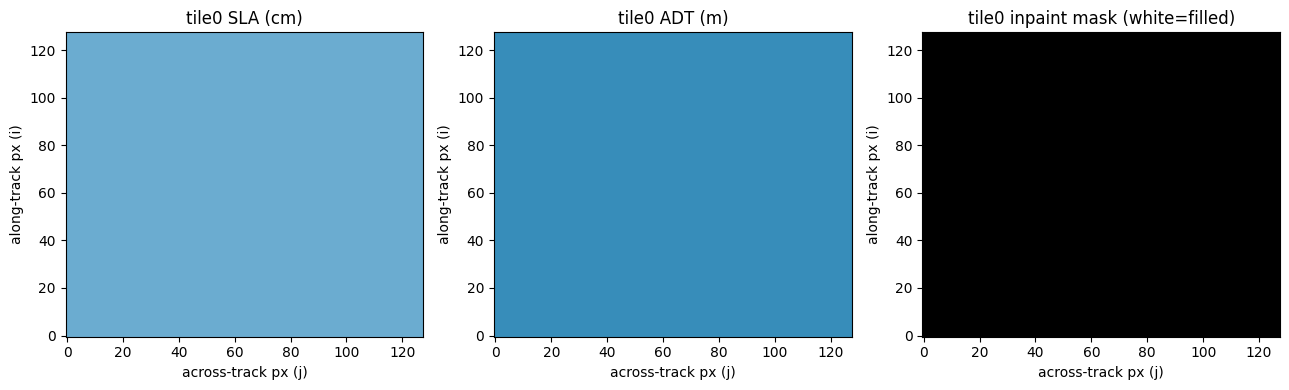

In [4]:
t = tiles[0]
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(t.data[0] * 100, cmap="RdBu_r", vmin=-10, vmax=30, origin="lower", aspect="auto")
ax[0].set_title("tile0 SLA (cm)")
ax[1].imshow(t.data[1], cmap="Spectral_r", vmin=-0.1, vmax=0.8, origin="lower", aspect="auto")
ax[1].set_title("tile0 ADT (m)")
ax[2].imshow(t.inpaint_mask[0], cmap="gray", origin="lower", aspect="auto")
ax[2].set_title("tile0 inpaint mask (white=filled)")
for a in ax:
    a.set_xlabel("across-track px (j)"); a.set_ylabel("along-track px (i)")
plt.tight_layout(); plt.show()

## Detect (py-eddy-tracker on SSHA)

In [5]:
dets, dsum = detect_pass(tiles, cfg, clon, clat, date)
print("detect summary:", dsum)

/mnt/c/Users/jspier/SWOT-eddy-ml/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:4824: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


detect summary: {'n_total': 56, 'n_nadir_reject': 6, 'n_gap_reject': 22, 'n_raw': 28, 'n_dedup': 16, 'n_anticyclonic': 6, 'n_cyclonic': 10, 'n_nadir_center': 3, 'channel': 'ssha'}


## Reassemble full-pass fields (what PET saw) for plotting

In [6]:
def stitch(tiles, n_lines):
    C, _, P = tiles[0].data.shape
    full = np.full((C, n_lines, P), np.nan)
    for t in tiles:
        h = t.data.shape[1]
        e = min(t.line_start + h, n_lines)
        full[:, t.line_start:e, :] = t.data[:, :e - t.line_start, :]
    return full

n_lines = summary["n_lines_cropped"]
full = stitch(tiles, n_lines)   # (2, n_lines, 128): channel 0 ssha, channel 1 adt
pad_left = tiles[0].pad_left
print("full field shape:", full.shape)

full field shape: (2, 1087, 128)


## Overlay: SSHA & ADT with detections

Contours are the **max-velocity (speed) contours**, like de Marez Fig. 1–2. Red =
anticyclonic, blue = cyclonic. **Dashed** = `gap_reject` (paper would drop: >40% of the
contour on gaps, or >60% if the center is in the nadir band). **×** marker = center in the
nadir gap. Dotted vertical lines mark the real-data columns (`pad_left … pad_left+69`).

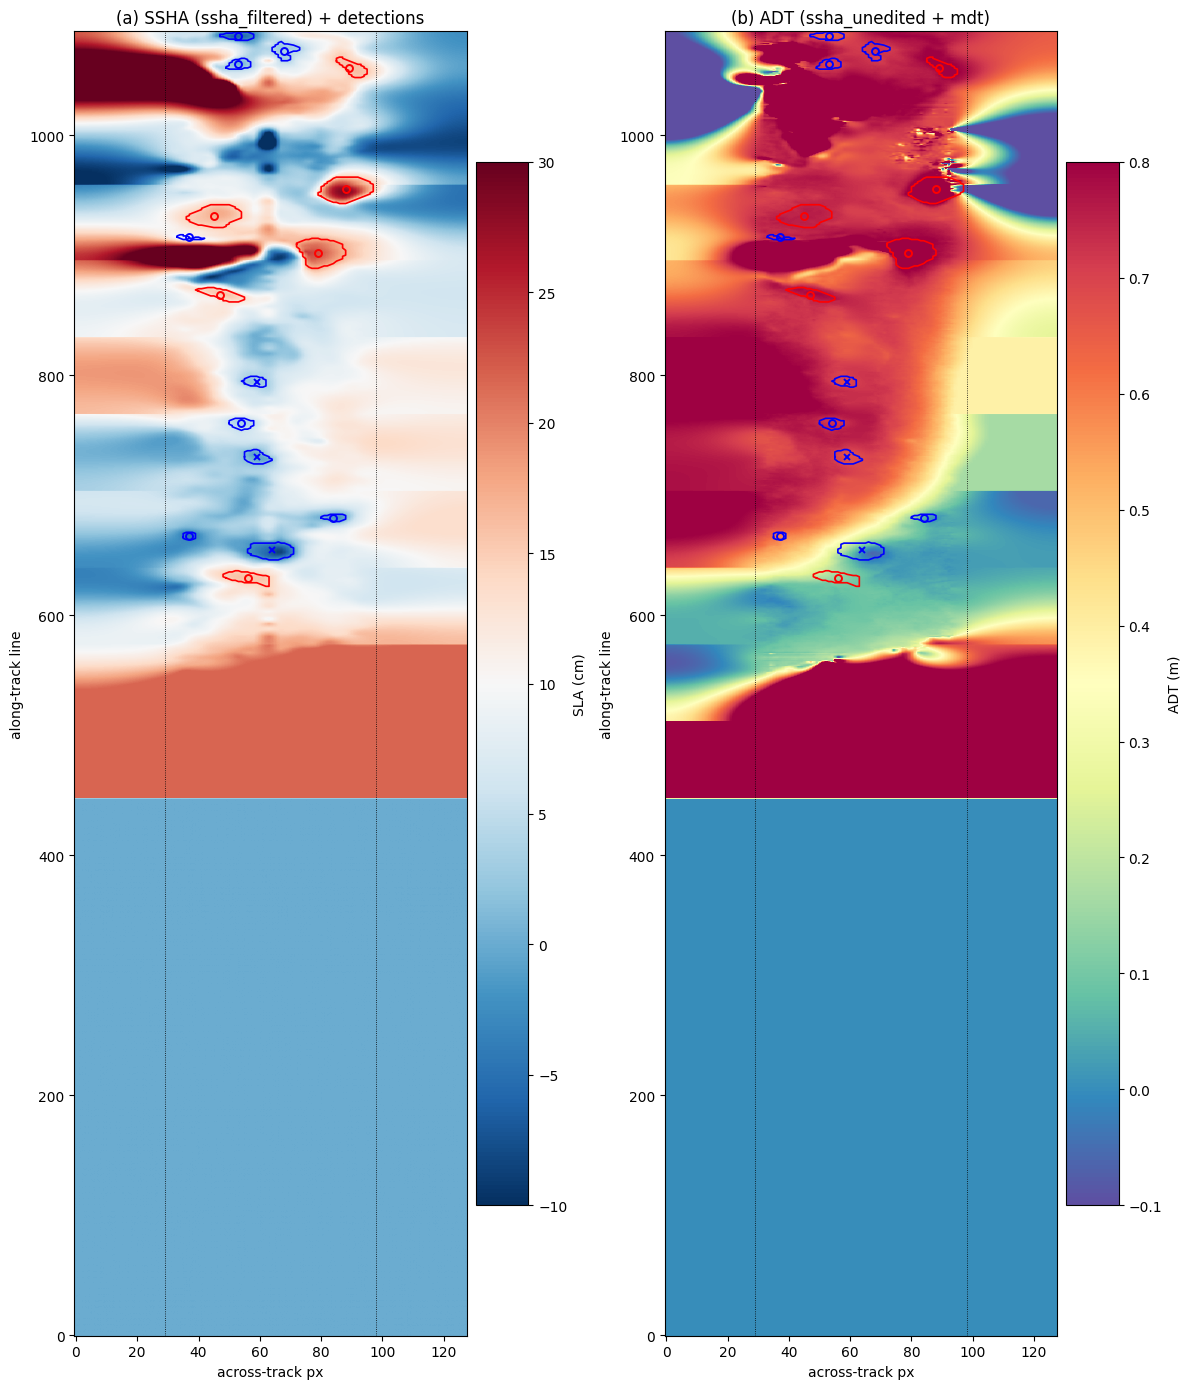

In [7]:
def overlay(ax, field2d, title, cmap, vmin, vmax, scale=1.0, label=""):
    im = ax.imshow(field2d * scale, cmap=cmap, vmin=vmin, vmax=vmax,
                   origin="lower", aspect="auto")
    ax.axvline(pad_left, color="k", lw=0.6, ls=":"); ax.axvline(pad_left + 69, color="k", lw=0.6, ls=":")
    for d in dets:
        c = "red" if d.polarity == "anticyclonic" else "blue"
        ls = "--" if d.gap_reject else "-"
        if d.contour_pix:
            cl = np.array(d.contour_pix)             # (N, 2) = (line, col)
            ax.plot(cl[:, 1], cl[:, 0], color=c, lw=1.2, ls=ls)
        mk = "x" if d.center_in_nadir else ("s" if d.gap_reject else "o")
        ax.plot(d.center_col, d.center_line, mk, color=c, ms=5, mfc="none", mew=1.4)
    ax.set_title(title); ax.set_xlabel("across-track px"); ax.set_ylabel("along-track line")
    fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02).set_label(label)

fig, ax = plt.subplots(1, 2, figsize=(12, 14))
overlay(ax[0], full[0], "(a) SSHA (ssha_filtered) + detections", "RdBu_r", -10, 30, scale=100, label="SLA (cm)")
overlay(ax[1], full[1], "(b) ADT (ssha_unedited + mdt)", "Spectral_r", -0.1, 0.8, label="ADT (m)")
plt.tight_layout(); plt.show()

## Per-eddy review panels — vet false positives

The full-pass strip (1089×128) squashes every eddy into a few pixels. Here each detection
is **cropped around its own center** and shown at true 2-km pixel aspect (circles look
circular), in **both** fields side-by-side: **SSHA** (`ssha_filtered`, what PET ran on) and
**ADT** (`ssha_unedited`+`mdt`, the physical reference). A real eddy shows a closed
SSHA anomaly AND a matching ADT swirl; a false positive usually looks like noise / a front
edge / a nadir-gap artifact in one or both.

Rows sorted by amplitude (strongest first). Red = anticyclonic, blue = cyclonic. Solid =
keep candidate, **dashed** contour = `gap_reject`. Marker: `o` clean, `s` gap-reject,
`×` center in nadir gap. Dotted verticals = real-data column band (`pad_left … +69`).
Title carries lon/lat, R_max, amplitude, and any ⚑ flags for the hand-approval log.

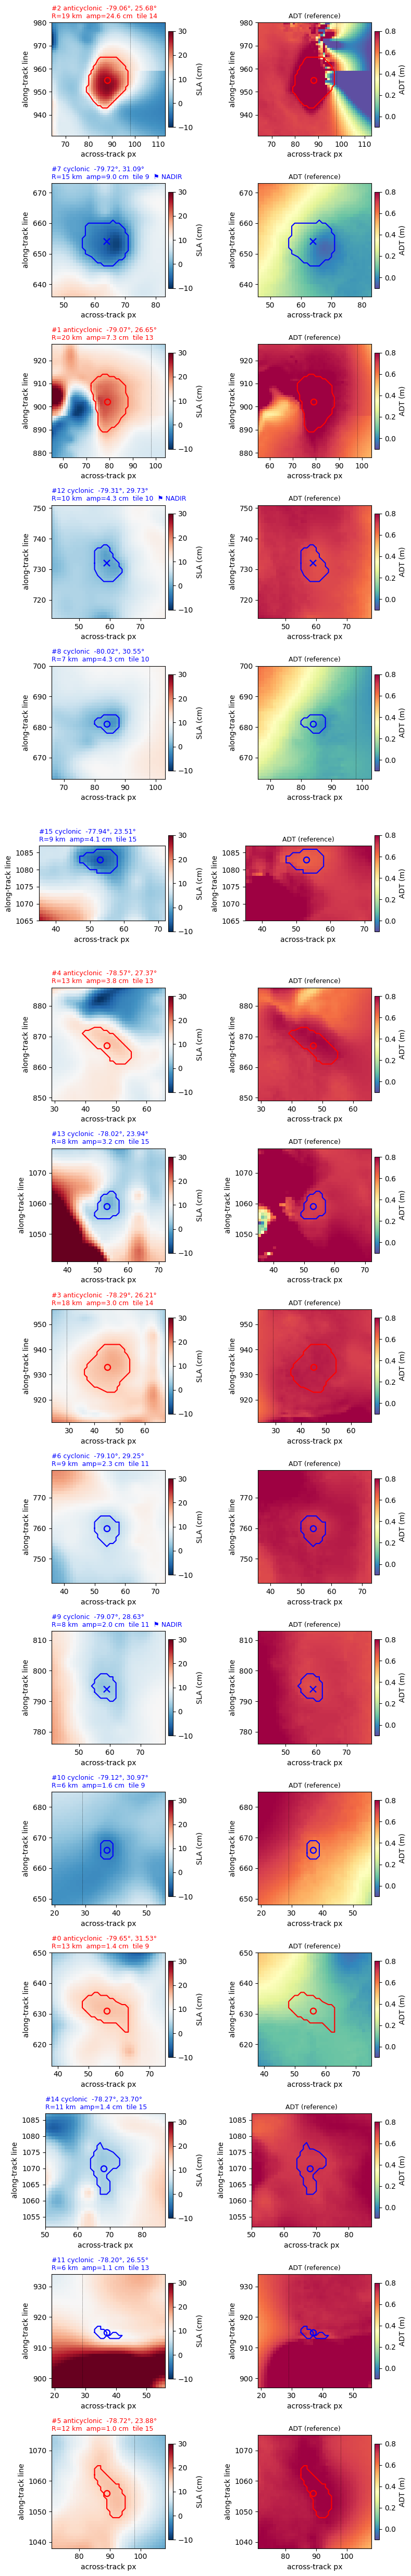

In [8]:
def eddy_panels(dets, full, pad_left):
    """One row per detection (sorted by amplitude): SSHA zoom | ADT zoom, true pixel aspect."""
    if not dets:
        print("no detections"); return
    order = sorted(range(len(dets)), key=lambda k: -dets[k].amplitude_m)
    ssha, adt = full[0] * 100.0, full[1]
    nL, nC = ssha.shape
    fig, axes = plt.subplots(len(order), 2, figsize=(8, 3.1 * len(order)), squeeze=False)
    for row, k in enumerate(order):
        d = dets[k]
        r_px = max(d.radius_km / 2.0, 6)                       # R_max in px (2 km/px)
        half = int(round(max(2.5 * r_px, 18)))                # crop half-window
        i0, i1 = max(0, d.center_line - half), min(nL, d.center_line + half + 1)
        j0, j1 = max(0, d.center_col - half),  min(nC, d.center_col + half + 1)
        col = "red" if d.polarity == "anticyclonic" else "blue"
        cls = "--" if d.gap_reject else "-"
        mk  = "x" if d.center_in_nadir else ("s" if d.gap_reject else "o")
        cont = np.array(d.contour_pix) if d.contour_pix else None
        for ax, fld, cmap, vmin, vmax, lbl in (
                (axes[row, 0], ssha, "RdBu_r",    -10, 30,  "SLA (cm)"),
                (axes[row, 1], adt,  "Spectral_r", -0.1, 0.8, "ADT (m)")):
            im = ax.imshow(fld[i0:i1, j0:j1], cmap=cmap, vmin=vmin, vmax=vmax,
                           origin="lower", aspect="equal", extent=[j0, j1, i0, i1])
            for xx in (pad_left, pad_left + 69):
                if j0 <= xx <= j1:
                    ax.axvline(xx, color="k", lw=0.5, ls=":")
            if cont is not None:
                ax.plot(cont[:, 1], cont[:, 0], color=col, lw=1.5, ls=cls)
            ax.plot(d.center_col, d.center_line, mk, color=col, ms=8, mfc="none", mew=1.7)
            ax.set_xlim(j0, j1); ax.set_ylim(i0, i1)
            ax.set_xlabel("across-track px"); ax.set_ylabel("along-track line")
            fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02).set_label(lbl)
        loc = "lon/lat n/a (pad)" if d.center_lon is None else f"{d.center_lon - 360:.2f}°, {d.center_lat:.2f}°"
        flags = []
        if d.gap_reject:      flags.append(f"GAP {d.gap_frac:.0%}")
        if d.center_in_nadir: flags.append("NADIR")
        tag = ("  ⚑ " + ", ".join(flags)) if flags else ""
        axes[row, 0].set_title(
            f"#{k} {d.polarity}  {loc}\nR={d.radius_km:.0f} km  amp={d.amplitude_m * 100:.1f} cm  tile {d.source_tile}{tag}",
            loc="left", fontsize=9, color=col)
        axes[row, 1].set_title("ADT (reference)", fontsize=9)
    plt.tight_layout(); plt.show()

eddy_panels(dets, full, pad_left)

## Native pass (raw, no preprocessing) + detections

Same detections overlaid on the **untouched** SWOT pass — `ssha_filtered` and ADT
(`ssha_unedited`+`mdt`) cropped to the box only: **no quality-mask, no biharmonic inpaint,
no pad**. Native 69-px across-track width (PET ran on a 128-px padded/inpainted copy, so
detection columns are shifted back by `pad_left`). White = real `NaN` gaps. Use this to
catch detections that PET only "saw" because inpainting invented signal in a gap — those
are the false positives to drop. Markers/colors as above.

native shape: (2, 1087, 69) | pad_left: 29 | swath edge cols: [0, 29, 39, 68] | NaN frac (ssha): 0.675


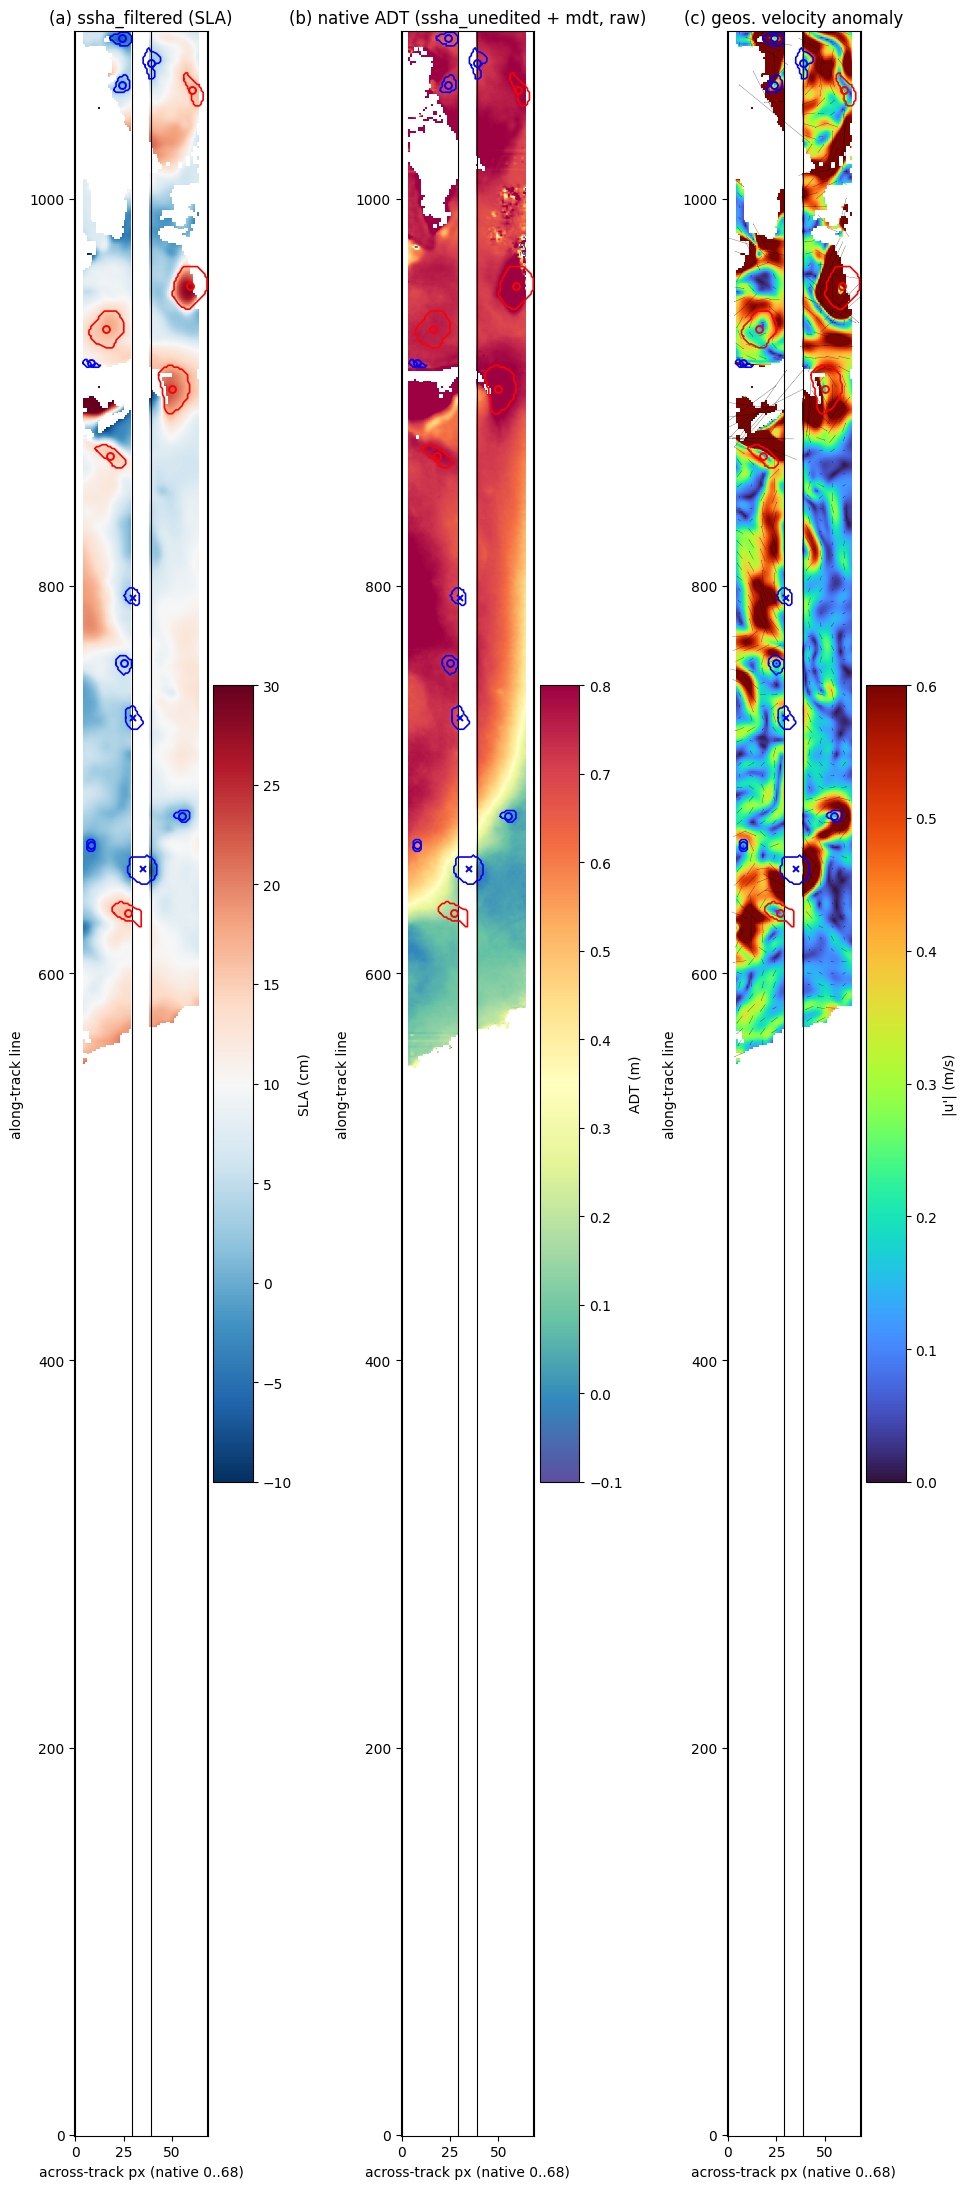

In [9]:
import xarray as xr

var_map = cfg["product"]["variables"][cfg["product"]["product_version"]]
with xr.open_dataset(str(path)) as ds_raw:
    ds_c, _ = pp.crop_to_region(ds_raw, cfg["region"])
    native, _, _ = pp.compute_channels(ds_c, var_map, quality_max=None)  # (2, L, 69) RAW
    ua, va = pp.geostrophic_anomaly_uv(ds_c, var_map)                    # (L, 69) ugosa, vgosa [m/s]
    edge_cols = pp.swath_edge_cols(ds_c)                                 # 4 swath edges (native cols)
speed_a = np.hypot(ua, va)
print("native shape:", native.shape, "| pad_left:", pad_left, "| swath edge cols:", edge_cols,
      "| NaN frac (ssha):", round(float(np.isnan(native[0]).mean()), 3))

def overlay_native(ax, fld2d, title, cmap, vmin, vmax, scale, label, quiver=False):
    # aspect="equal" -> native 2-km pixel proportions (true swath shape, undistorted)
    im = ax.imshow(fld2d * scale, cmap=cmap, vmin=vmin, vmax=vmax, origin="lower", aspect="equal")
    for c in edge_cols:                                       # 4 SWOT swath-edge lines
        ax.axvline(c, color="k", lw=0.8)
    if quiver:                                                # anomaly velocity vectors (real obs only)
        s = 6
        XX, YY = np.meshgrid(np.arange(0, native.shape[2], s), np.arange(0, native.shape[1], s))
        ax.quiver(XX, YY, ua[::s, ::s], va[::s, ::s], color="k",
                  angles="xy", scale_units="xy", scale=0.06, width=0.0018, pivot="mid")
    for d in dets:
        c = "red" if d.polarity == "anticyclonic" else "blue"
        ls = "--" if d.gap_reject else "-"
        if d.contour_pix:
            cl = np.array(d.contour_pix, dtype="f8"); cl[:, 1] -= pad_left   # padded -> native col
            ax.plot(cl[:, 1], cl[:, 0], color=c, lw=1.2, ls=ls)
        mk = "x" if d.center_in_nadir else ("s" if d.gap_reject else "o")
        ax.plot(d.center_col - pad_left, d.center_line, mk, color=c, ms=5, mfc="none", mew=1.4)
    ax.set_xlim(-0.5, native.shape[2] - 0.5)
    ax.set_title(title); ax.set_xlabel("across-track px (native 0..68)"); ax.set_ylabel("along-track line")
    fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02).set_label(label)

# 4 black lines = SWOT swath edges (2 outer + 2 nadir-gap borders). (c) = velocity anomaly +
# ugosa/vgosa vectors (like geostrophic.py fig 2); arrows only where real data exists.
fig, ax = plt.subplots(1, 3, figsize=(10, 22))
overlay_native(ax[0], native[0], "(a) ssha_filtered (SLA)", "RdBu_r", -10, 30, 100, "SLA (cm)")
overlay_native(ax[1], native[1], "(b) native ADT (ssha_unedited + mdt, raw)", "Spectral_r", -0.1, 0.8, 1.0, "ADT (m)")
overlay_native(ax[2], speed_a, "(c) geos. velocity anomaly", "turbo", 0, 0.6, 1.0, "|u'| (m/s)", quiver=True)
plt.tight_layout(); plt.show()

## Detection table — manual review surface\n`radius_km` = R_max (speed radius); `gap_rej` = paper reject flag.

In [10]:
try:
    import pandas as pd
    df = pd.DataFrame([{
        "polarity": d.polarity, "line": d.center_line, "col": d.center_col,
        "lon": None if d.center_lon is None else round(d.center_lon, 3),
        "lat": None if d.center_lat is None else round(d.center_lat, 3),
        "radius_km": round(d.radius_km, 1), "amp_m": round(d.amplitude_m, 3),
        "gap_frac": round(d.gap_frac, 2), "gap_rej": d.gap_reject,
        "nadir": d.center_in_nadir, "tile": d.source_tile,
    } for d in dets]).sort_values("amp_m", ascending=False)
    display(df)
except ImportError:
    for d in sorted(dets, key=lambda d: -d.amplitude_m):
        print(d.polarity[:4], d.center_line, d.center_col, round(d.radius_km, 1),
              round(d.amplitude_m, 3), "REJECT" if d.gap_reject else "", "nadir" if d.center_in_nadir else "")

,polarity,line,col,lon,lat,radius_km,amp_m,gap_frac,gap_rej,nadir,tile
2,anticyclonic,955,88,280.941,25.677,19.3,0.246,0.30,False,False,14
7,cyclonic,654,64,280.282,31.094,14.6,0.090,0.56,False,True,9
1,anticyclonic,902,79,280.927,26.647,19.5,0.073,0.07,False,False,13
8,cyclonic,681,84,279.980,30.546,6.7,0.043,0.00,False,False,10
12,cyclonic,732,59,280.691,29.729,9.9,0.043,0.52,False,True,10
15,cyclonic,1083,53,282.062,23.512,8.9,0.041,0.00,False,False,15
4,anticyclonic,867,47,281.435,27.372,12.6,0.038,0.00,False,False,13
13,cyclonic,1059,53,281.982,23.939,8.3,0.032,0.00,False,False,15
3,anticyclonic,933,45,281.708,26.206,17.7,0.030,0.00,False,False,14
6,cyclonic,760,54,280.900,29.249,8.8,0.023,0.00,False,False,11


## Manual review — Keep / Reject each eddy

Interactive vetting. One candidate at a time. Pixel zooms (top, true 2-km aspect):
**(a) SLA** (detection field) · **(b) ADT** (reference) · **(c) geos. velocity ANOMALY**
`√(ugosa²+vgosa²)`+vectors — real eddy = bright rotation ring · **(d) geos. velocity FULL**
(`ugos/vgos`, includes mean flow) · **(e) wide context** (~4× zoom-out, dashed box = the zoom
window). Then full-swath-in-box with coastline (bottom): **(f) SSHA · (g) ADT · (h) geos.
speed anomaly**. Speed contour + center marker on each.

Click **Keep ✓**, **Reject ✗**, **Skip**; **◀ Back / Next ▶** to move without deciding.
**Hotkeys**: `k` keep, `r` reject, `s` skip, `←`/`→` nav. Every click writes
`out/labels/decisions.csv` keyed `(cycle, pass, eddy)` — **resumable**: re-running picks up
where you left off. False positive = front edge / noise / nadir artifact (`⚑` flags).
Needs `ipywidgets` (Colab has it; else `pip install ipywidgets`).

In [ ]:
from swot_eddy.review import EddyReviewer, kept_detections

_to180 = lambda lo: ((lo + 180) % 360) - 180
with xr.open_dataset(str(path)) as _ds:                    # native lon/lat + fields for (f)/(g)/(h)
    _dc, _ = pp.crop_to_region(_ds, cfg["region"])
    _gu, _gv = pp.geostrophic_anomaly_uv(_dc, var_map)     # ugosa/vgosa for geo-row speed panel
    _uf, _vf = _dc[var_map["ugos"]].values, _dc[var_map["vgos"]].values   # full ugos/vgos -> panel (d)
    geo = (_to180(_dc.longitude.values), _dc.latitude.values,
           _dc[var_map["ssha"]].values * 100.0,
           (_dc[var_map["ssha_adt_base"]] + _dc[var_map["mdt"]]).values,
           _gu, _gv)

cycle = path.parent.name                                   # e.g. "cycle_043"
labels_path = Path(cfg["out_root"]) / "labels" / "decisions.csv"
EddyReviewer(dets, full, pad_left, uv=(ua, va), uv_full=(_uf, _vf), edge_cols=edge_cols, geo=geo,
             cycle=cycle, pass_name=path.stem, labels_path=labels_path).show()
# panels: (a) SLA (b) ADT (c) geos. vel ANOMALY (d) geos. vel FULL ugos/vgos (e) wide context
#         (f) SSHA (g) ADT (h) geos. speed anomaly on full swath + coast

In [13]:
# After reviewing: the human-kept eddies for this pass (from decisions.csv).
keep = kept_detections(dets, cycle, path.stem, labels_path)
print(f"kept {len(keep)} of {len(dets)} candidates")
for d in sorted(keep, key=lambda d: -d.amplitude_m):
    loc = "n/a" if d.center_lon is None else f"{d.center_lon-360:.2f}E,{d.center_lat:.2f}N"
    print(f"  {d.polarity[:4]}  {loc}  R={d.radius_km:.0f}km  amp={d.amplitude_m*100:.1f}cm")

kept 11 of 16 candidates
  anti  -79.06E,25.68N  R=19km  amp=24.6cm
  cycl  -79.72E,31.09N  R=15km  amp=9.0cm
  anti  -79.07E,26.65N  R=20km  amp=7.3cm
  cycl  -79.31E,29.73N  R=10km  amp=4.3cm
  cycl  -80.02E,30.55N  R=7km  amp=4.3cm
  cycl  -77.94E,23.51N  R=9km  amp=4.1cm
  cycl  -78.02E,23.94N  R=8km  amp=3.2cm
  anti  -78.29E,26.21N  R=18km  amp=3.0cm
  cycl  -79.10E,29.25N  R=9km  amp=2.3cm
  cycl  -79.12E,30.97N  R=6km  amp=1.6cm
  anti  -79.65E,31.53N  R=13km  amp=1.4cm


## Kept eddies on the original SWOT swath (geographic, no interpolation)

Final view: the **kept** eddies plotted on the **native curved/tilted SWOT swath** in true
`longitude/latitude` — `pcolormesh` over the 2-D lon/lat grid, native cells, **no
interpolation, not the straightened pixel grid**. Speed contours + centers in geographic
coords; **(c)** carries the `ugosa/vgosa` velocity-anomaly vectors. No cartopy needed (no
coastlines; install `cartopy` if you want land/coast). Plots `keep` if you've reviewed,
else all `dets`.

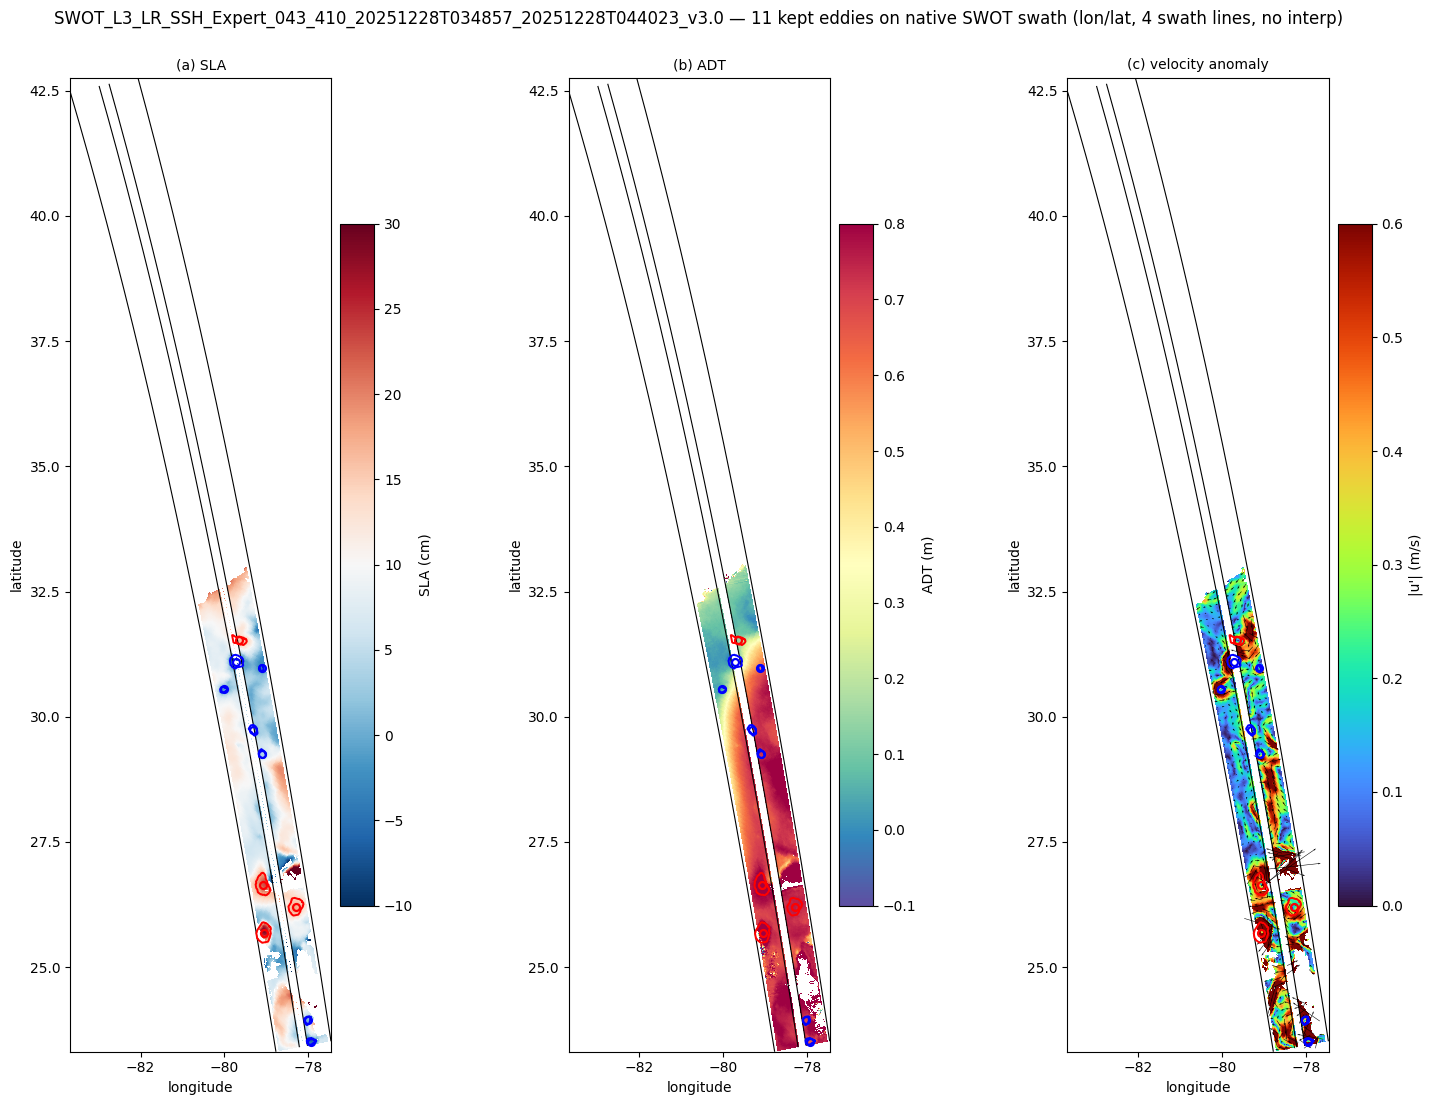

In [14]:
# Native SWOT swath in geographic coords (lon/lat), no interpolation. Needs no cartopy.
sel = keep if keep else dets
with xr.open_dataset(str(path)) as ds_raw:
    dsg, _ = pp.crop_to_region(ds_raw, cfg["region"])
to180 = lambda lo: ((lo + 180) % 360) - 180
glon = to180(dsg.longitude.values); glat = dsg.latitude.values       # (L, 69) real geolocation
gsla = dsg[var_map["ssha"]].values * 100.0                            # cm, native (NaN gaps)
gadt = (dsg[var_map["ssha_adt_base"]] + dsg[var_map["mdt"]]).values   # m
gu, gv = dsg[var_map["ugosa"]].values, dsg[var_map["vgosa"]].values   # m/s
gedges = pp.swath_edge_cols(dsg)                                      # 4 swath-edge columns
midlat = float(np.nanmean(glat))

def geo_panel(ax, fld, cmap, vmin, vmax, label, title, quiver=False):
    pm = ax.pcolormesh(glon, glat, fld, cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest")
    for c in gedges:                                          # 4 SWOT swath-edge lines (track curves)
        ax.plot(glon[:, c], glat[:, c], color="k", lw=0.8)
    if quiver:
        s = 7
        ax.quiver(glon[::s, ::s], glat[::s, ::s], gu[::s, ::s], gv[::s, ::s],
                  color="k", scale=15, width=0.002, pivot="mid")
    for d in sel:
        c = "red" if d.polarity == "anticyclonic" else "blue"
        cl = [p for p in d.contour_lonlat if p is not None]
        if cl:
            a = np.array(cl); ax.plot(to180(a[:, 0]), a[:, 1], color=c, lw=1.4)
        if d.center_lon is not None:
            ax.plot(to180(d.center_lon), d.center_lat, "o", color=c, ms=5, mfc="none", mew=1.6)
    ax.set_aspect(1 / np.cos(np.deg2rad(midlat)))            # equal ground distance at this latitude
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title(title, fontsize=10)
    fig.colorbar(pm, ax=ax, shrink=0.7, pad=0.02).set_label(label)

fig, ax = plt.subplots(1, 3, figsize=(15, 11))
geo_panel(ax[0], gsla, "RdBu_r", -10, 30, "SLA (cm)", "(a) SLA")
geo_panel(ax[1], gadt, "Spectral_r", -0.1, 0.8, "ADT (m)", "(b) ADT")
geo_panel(ax[2], np.hypot(gu, gv), "turbo", 0, 0.6, "|u'| (m/s)", "(c) velocity anomaly", quiver=True)
fig.suptitle(f"{path.stem} — {len(sel)} kept eddies on native SWOT swath (lon/lat, 4 swath lines, no interp)", y=1.0)
plt.tight_layout(); plt.show()

## Label the WHOLE catalog — every eddy, every pass (ML training labels)

Walks **every detection across all passes** in **two phases**: **(1)** all the KEPT (good)
eddies first, then **(2)** all the auto-REJECTED ones (nadir/gap blobs) as training negatives
— so you label clean data before slogging through false positives.

Per eddy, **8 panels**. Pixel zooms (top row): **(a) SLA · (b) ADT · (c) geos. velocity
ANOMALY (ugosa/vgosa) · (d) geos. velocity FULL (ugos/vgos, incl. mean flow) · (e) wide
context**. Then on the **full SWOT swath across the whole box in lon/lat with coastline**
(cartopy, like F1_v52, bottom row): **(f) SSHA · (g) ADT · (h) geos. speed anomaly** (+
vectors), eddy marked, so you see where it sits relative to the front/coast and judge
frontal-ness.

Buttons = your class set (default **frontal / non-frontal / reject**) + Skip + Back/Next.
**Hotkeys**: `1`/`2`/`3` = labels, `s` = skip, `←`/`→` = back/next (no click needed).
**Polarity is not hand-labeled** — PET sets it from SLA sign (neg=cyclonic / pos=anticyclonic),
shown red/blue so you can eyeball sign flips. Each click writes `out/labels/eddy_labels.csv`
keyed `(cycle, pass, kind, eddy)` — **resumable**: relaunch jumps to the first unlabeled eddy.

Run `scripts/run_all.py` first. Within a pass eddy↔eddy is instant; new pass re-detects
(~10–30 s). Scope with `cycles=[...]`. (f)/(g)/(h) coastline needs `cartopy` (installed).

In [6]:
from swot_eddy.review import CatalogLabeler

# Label every eddy across all passes. 
CatalogLabeler(cfg, labels=("frontal", "non-frontal", "reject")).show()

/mnt/c/Users/jspier/SWOT-eddy-ml/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:4824: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


<IPython.core.display.Javascript object>

## Parameters (de Marez vs recall)

Detection runs on `ssha_filtered`, **no high-pass**. Knobs in `config.yaml` `pet.params`:
- **`pixel_limit_min`** — set to **4** to match de Marez (PET-standard). Was 3 for higher
  small-eddy recall.
- **`shape_error = 85`** — paper value (maximizes detections).
- `step = min_amplitude_m / 2` → amplitude floor `min_amplitude_m` (0.01 m); min radius 5 km on R_max.

Detections are flagged, not dropped — carry false positives to the hand-approval step.

In [15]:
p = cfg["pet"]["params"]
print("shape_error:", p["shape_error"], "| min_amplitude_m:", p["min_amplitude_m"],
      "| min_radius_km:", p["min_radius_km"],
      "| pixel_limit:", (p.get("pixel_limit_min", 4), p.get("pixel_limit_max", 1000)),
      "(de Marez = (4, 1000))")

shape_error: 85 | min_amplitude_m: 0.01 | min_radius_km: 5 | pixel_limit: (4, 1000) (de Marez = (4, 1000))
